### Foundations of Finance
# Python Practice #3: Yield Curve Calibration

---
## 1. **Read:** Introduction

We have seen how to "complete" or fit a yield curve to appropriately value bonds using the simplest case of linear interpolation.  
Now, let's see how can we fit a yield curve using more complex techniques.  

The Nelson-Siegel (1987) model is probably the most universally used model for modelling the **Term Structure of Interest Rates (TSIR)**.  
In this notebook we are going to see the main intuition and inner mechanics of the model so to develop a sense on how to properly fit a yield curve.

This is a parametric factor model, that basically models the **yield** of **Zero-Coupon bonds**, $r(t)$, as a constant plus some polynomial with an exponential decay term (in essence, a Laguerre function).  
The mathematical formulation would be as follows (following Diebold and Li, 2006):

$$r(t) = \beta_0 + \beta_1 \left[ \frac{1-e^{-\lambda t}}{\lambda t} \right] + \beta_2 \left[ \frac{1-e^{-\lambda t}}{\lambda t} - e^{-\lambda t} \right]$$

- *where $\lambda = \frac{1}{\tau}$ in the original Nelson and Siegel (1987) formulation and:*
- $\beta_0$ is the **long-term factor (long-term interest rate)**
- $\beta_1$ proxies for the **short-term factor** (i.e., relationship between short and long-term rates $\rightarrow$ Slope)
- $\beta_2$ proxies for **medium-term factor** (i.e., shape of the curve $\rightarrow$ Curvature)

If we think about it, the model formulation actually makes a lot of sense.For example we could **interpret**:

- when $t \rightarrow \infty$, the importance (loading) of $\beta_1$ and $\beta_2$ tend to 0, and $r(t) \rightarrow \beta_0$, the long-term interest rate.
- when $t \rightarrow 0$, the loading on $\beta_1$ (short-term factor) becomes the most important one, followed by the mid-term factor, $\beta_2$.

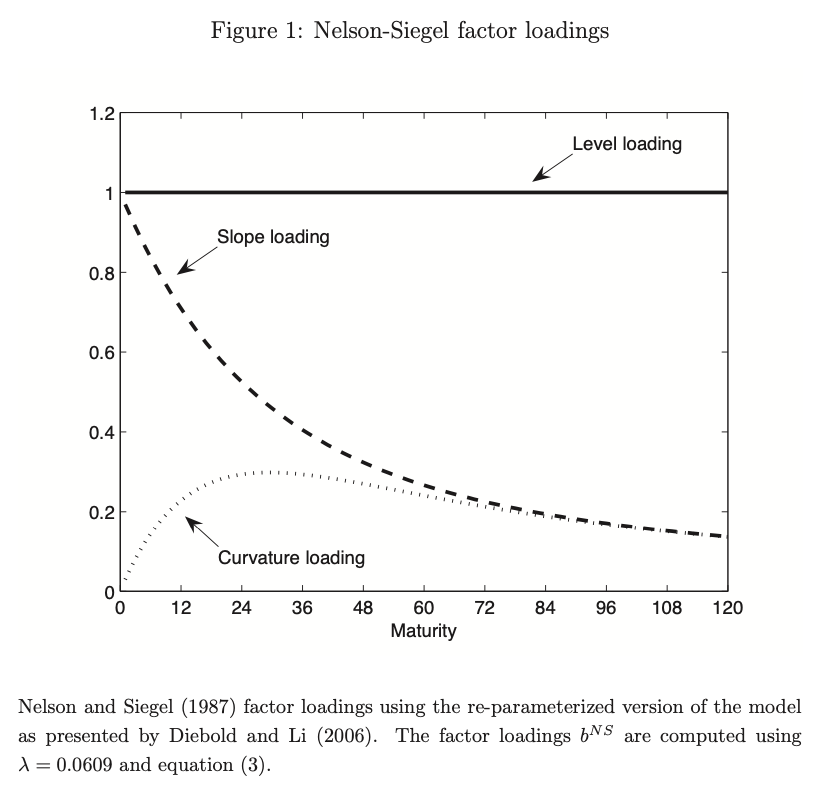

---
### Now, let's work with the model to fit our own yield curve!
---
## 2. **Run:** Prepare the environment

For simplicity, let's use an already existent python package [nelson_siegel_svensson](https://github.com/luphord/nelson_siegel_svensson) for this purpose.  
Let's start by importing (and installing when needed) all the necessary libraries for the task:
- [numpy](https://numpy.org/): numerical methods.
- [pandas](https://pandas.pydata.org/): data manipulation.
- [nelson_siegel_svensson](https://github.com/luphord/nelson_siegel_svensson): curve calibration ([more docs](https://nelson-siegel-svensson.readthedocs.io/en/latest/))
- [plotly](https://plotly.com/): interactive plots.  

All required packages must be installed before they are imported. The installation procedure depends on your specific Python setup. Using the default package manager `pip` should work in most cases.  

**IMPORTANT:** Are you using Google Colab? Then you probably need to install `nelson_siegel_svensson` from the command-line.  

The command-line is available in jupyter notebooks using `!` at the beginning of the line (you have to remove the comment `#` for the command below to work).

In [ ]:
!pip install nelson_siegel_svensson

The imports, as required:

In [ ]:
# data manipulation
import numpy as np
import pandas as pd

# Nelson Siegel Svensson
from nelson_siegel_svensson import NelsonSiegelCurve
from nelson_siegel_svensson.calibrate import calibrate_ns_ols

# Graphical libraries
import plotly.express as px
import plotly.graph_objs as go
from plotly.subplots import make_subplots

---
## 3. **Web:** Check U.S. Daily Treasury Yield Curve Rates on the Internet

Imagine that we want to fit the yields of a **US Treasury Bond**.  
The outstanding maturities and yields of the bonds that the United States of America currently have in the market are accessible here:

https://home.treasury.gov/policy-issues/financing-the-government/interest-rate-statistics

Take some time to navigate the page and understand what it provides.

---
## 4. **Run:** Download (in Python) the U.S. Daily Treasury Yield Curve Rates

However, instead of downloading manually the CSV file and then loading it in Python, it can be retrieved directly from the web providing the appropriate URL to `pandas`.  

We have looked up the URL in the browser and copied/pasted it for you.  
The month and year of the query are specified in `DATE` (e.g. `'202308'` stand for "August, 2023")  

**Run the cell and try to understand all the figures.**

In [ ]:
DATE = '202308'
URL = f'https://home.treasury.gov/resource-center/data-chart-center/interest-rates/daily-treasury-rates.csv' \
    + f'/all/{DATE}?type=daily_treasury_yield_curve&field_tdr_date_value_month={DATE}&page&_format=csv'

df = pd.read_csv(URL)
df.head()

---
## 5. **Exercise:** Transform the downloaded data into a two-column `DataFrame`

Please follow these steps (around 4 lines of code) to transform the data retrieved above into a format usable by the `nelson-siegel` package:
1. Pick just the row with the most recent date (**hint:** `.iloc[0]` for top row)
2. Drop column `Date`.
3. Translate the tenors into numerical values, that is, provide years as numbers instead of text labels. Months must be encoded as $1/{12^{th}}$ of a year. This step can be done manually, providing a hardcoded list of years. Do not bother to automate it.
5. The method `.values` strips the original index, returning just the yields. Maintaining  the original index would cause problems and make the next steps harder.
6. Remember to divide the yields by 100 (originally, they are percentages).
7. Assemble the tenors and the yields as columns of a new `DataFrame`.

The expected result should be a `DataFrame` named `market_data` that look like this:

| tenor |  yield |   
|-------|------- |
| $\frac{1}{12}$ | $\frac{y_1}{100}$  |
| $\frac{2}{12}$ | $\frac{y_2}{100}$  |
| $\frac{3}{12}$ | $\frac{y_3}{100}$  |
| ...   | ...    |
| $t_n$ | $\frac{y_n}{100}$  |

**NOTE:** the term **tenor** describes the length of time remaining in the life of a financial contract. By contrast, **maturity** refers to the initial length of a contract upon its inception.

In [ ]:
rec_date = df.head(1).drop(columns='Date')
rec_date.columns = [1/12, 2/12, 3/12, 4/12, 6/12, 1, 2, 3, 5, 7, 10, 20, 30]
rec_date.loc[:, :] = rec_date.values / 100

In [ ]:
market_data = rec_date.reset_index().melt(id_vars='index', var_name='tenor', value_name='yield')[['tenor', 'yield']]
print(market_data.to_string(index=False))

---
## 6. **Run:** Life is nicer with plots
This helper function draws points and/or up to two curves in the same plot.  

**Out of scope:** don't worry too much about the inner workings of [Plotly](https://plotly.com/python/line-and-scatter/) graphic package. Copy and Paste this cell and use the function wherever you need it...

In [ ]:
def plot_curve(title,
               points=None, points_name='points',
               curve1=None, curve1_name='curve1',
               curve2=None, curve2_name='curve2'):
    """ this function takes three pairs or arguments: points, curve1 and curve2 """
    
    # create base figure
    fig = go.Figure()

    if points is not None:
        # plot points, if provided
        fig.add_trace(go.Scatter(
            x = points['tenor'],
            y = points['yield'],
            mode='markers',
            name=points_name))

    for curve, name in [(curve1, curve1_name), (curve2, curve2_name)]:
        if curve is not None:
            # plot curve, if provided
            fig.add_trace(go.Scatter(
                x = curve['tenor'],
                y = curve['yield'],
                mode='lines',
                name=name))

    # title, axis labels, and percentages in vertical axis (y)
    fig.update_layout(
        width=800,
        height=400,
        yaxis= { 'tickformat': '.1%'},
        title=title,
        xaxis_title='tenors [years]',
        yaxis_title='yield [%]',
    )

    fig.show()

Let's use the function above to display the data points.

In [ ]:
plot_curve('Market observed data', points=market_data)

---
## 7. **Run:** Nelson-Siegel TSIR calibration

For your convenience, the function `apply_nelson_siegel()` performs the following tasks in a single call:
1. calibrates the Nelson-Siegel curve given the market yields and tenors as inputs (`market_data`).
2. calculates the rates at `my_tenors`.  

The $\beta_0$, $\beta_1$, $\beta_2$ and $\tau$ are printed in the output (double-check that `success=True` as well).  

This function also displays:
- A plot with the market data vs. the fitted curve.
- A plot with the fitted curve and the forward rates (out of scope, more on this later...).

In [ ]:
def apply_nelson_siegel(market_data,
                        my_tenors):
    """ market_data contains the table downloaded from the US Treasury, my_tenors are the values of t when the rates must be calculated """
    
    # 1. calibrate the model
    market_tenors = market_data['tenor'].values.astype(float)
    market_yields = market_data['yield'].values.astype(float)
    # print(market_tenors)
    print(market_yields)
    model, status = calibrate_ns_ols(market_tenors, market_yields)
    print(model)
    print(status)
    
    # 2. let's calculate 200 points to draw some graphics
    plot_tenors = np.linspace(0, max(market_tenors), 200)
    
    # 3. For these points, calculate the yields
    plot_yields = NelsonSiegelCurve.zero(model, plot_tenors)
    plot_yield_data = pd.DataFrame()
    plot_yield_data['tenor'] = plot_tenors
    plot_yield_data['yield'] = plot_yields
    
    # 4. calculate forward yield as well (out of scope)
    plot_forward_yields = NelsonSiegelCurve.forward(model, plot_tenors)
    plot_forward_data = pd.DataFrame()
    plot_forward_data['tenor'] = plot_tenors
    plot_forward_data['yield'] = plot_forward_yields
    
    # 5. plot the market data (points) and the fitted curve (continuous)
    plot_curve('Calibrated Nelson-Siegel TSIR curve',
               points=market_data, points_name='observed rates',
               curve1=plot_yield_data, curve1_name='NS curve')
    
    # 6. plot a comparison between rates and forward rates
    plot_curve('Forward yield (out of scope)',
               curve1=plot_yield_data, curve1_name='yield',
               curve2=plot_forward_data, curve2_name='forward yield')
    
    # 7. Finally, calculate the specific points the user requested, return them as result
    my_yields = NelsonSiegelCurve.zero(model, my_tenors)
    result = pd.DataFrame()
    result['tenor'] = my_tenors
    result['yield'] = my_yields
    result = result.set_index('tenor')
    
    return result

---
## 8. **Run:** First steps in bond valuation

Consider the following exercise:

> Corporation XYZ is planning a new bond issue to finance their new investment project. The issue will consist on 500,000 bonds with face value $1,000 and a maturity of 25 years. The bonds will pay 5\% coupon annually. Given the volatility and risk of firm's XYZ business', investors will apply an spread of 2.5\% over the US-Treasury Bond Yields. **Value the whole bond issue using the appropriate discount rate from the calibrated TSIR from U.S. Government.**  

To price the bond, we require the appropriate yields for 25 years.  
The data available in the web does not cover every tenor in that period, so we need to use the `nelson-siegel` model to fill the gaps in the curve.  
To do that, we follow these steps:
1. Create the list of tenors (i.e., in this example 1, 2, 3, ..., 25)
2. Callibrate the model
3. Apply the model at every tenor in the list

For the first step, you may use the function `arange()` ([docs](https://numpy.org/doc/stable/reference/generated/numpy.arange.html)) or, alternatively, `linspace()` ([docs](https://numpy.org/doc/stable/reference/generated/numpy.linspace.html)). In the former you specify the size of the increment, in the latter the number of periods.

The function `apply_nelson_siegel()` will fulfill the last two steps.

In [ ]:
my_tenors = np.arange(1, 25+1, 1)

Call our function.  
The list of tenors is displayed below the plots.

In [ ]:
result = apply_nelson_siegel(market_data, my_tenors)
result

---
## 9. **Bonus:** Forward rates explanation

A central part (yet unmentioned until now) of the Nelson-Siegel type models is the modelling of the Forward rate. 

But, what is the **Forward rate**?

In essence, the yield that you *infer* you would be able to obtain on a future time $t_1$, from holding a security (e.g., a T-bond) until $t_2$, with $t_2>t_1$.

Mathematically (using compounded interest) this could be expressed as:

$$(1+r_1)^{t_1}(1+f_{t_1,t_2})^{t_2-t_1}= (1+r_2)^{t_2}$$

where $f_{t_1,t_2}$ is the forward rate from $t_1$ to $t_2$.

As you can expect, the Nelson-Siegel model also offers a *'closed-form'* solution to Forward yields. **Actually, we have not talked about this (out of the scope), but the whole derivation of NS comes from instantaneous forward rates.**

Given the shape of TSIR, where do you think the Forward yield curve will place in the graph?

---
## 10. **Bonus:** How to plot TSIR out of the ZCB **prices** observed in the market
Let's use these hypothetical ZCB prices:

In [ ]:
zcb = pd.DataFrame()
zcb['tenor'] = [ 0.5 ,  1.0 ,  2.0 ,  3.0 ,  5.0 , 10.0 , 30.0 ]
zcb['price'] = [99.99, 99.97, 99.25, 98.42, 97.35, 96.55, 93.12]
zcb

Calculate `yield`using the equation below:

$$price = \frac{100}{ \left( 1+yield \right)^t}$$

$$yield = \left( \frac{100}{price} \right)^{\frac{1}{t}} - 1$$

In [ ]:
zcb['yield'] = ((100/zcb['price'])**(1/zcb['tenor'])-1)
zcb

In [ ]:
apply_nelson_siegel(zcb, my_tenors)

---
# The End